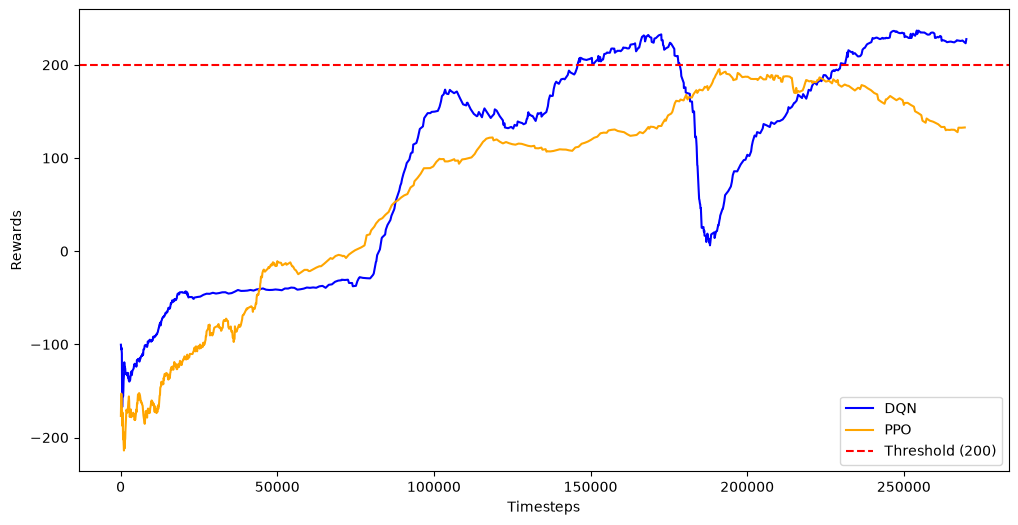

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from stable_baselines3.common.results_plotter import load_results, ts2xy

def moving_average(values, window):
    weights = pd.Series(values)
    return weights.rolling(window=window, min_periods=1).mean()

dqn_x , dqn_y = ts2xy(load_results("logs/Training_DQN"), 'timesteps')
ppo_x , ppo_y = ts2xy(load_results("logs/Training_PPO"), 'timesteps')

dqn_y_smoothed = moving_average(dqn_y, window=50)
ppo_y_smoothed = moving_average(ppo_y, window=50)

plt.figure(figsize=(12, 6))

plt.plot(dqn_x, dqn_y_smoothed, label='DQN', color='blue')
plt.plot(ppo_x, ppo_y_smoothed, label='PPO', color='orange')    

plt.axhline(y=200, color='r', linestyle='--', label='Threshold (200)')

plt.xlabel('Timesteps')
plt.ylabel('Rewards')
plt.legend()
plt.show()